
# DummyRegressor — Cross-validation estratificado

Este notebook implementa um baseline com `DummyRegressor` usando a mesma lógica de validação estratificada usada nos modelos CNN:

- divisão por `StratifiedKFold`;
- estratificação por região + classe de altura;
- target `rh_opt_098` convertido de cm para metros;
- métricas: RMSE, %RMSE, MAE, R², Bias e covariância;
- métricas por fold, por região e por classe de altura;
- gráficos de comparação, scatter true-vs-pred, bias por classe e boxplot de erro absoluto.

O `DummyRegressor` não usa os valores dos rasters. Ele serve como baseline: prevê sempre uma estatística do treino, por exemplo a média.


In [6]:

# ============================================================
# 1. IMPORTS E CONFIGURAÇÃO GLOBAL
# ============================================================

import os
import re
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from IPython.display import display

# -----------------------------
# Caminhos
# -----------------------------
# Pasta que contém:
#   patch_3x3/
#   patch_5x5/
#   patch_7x7/
#   patch_11x11/
#   patch_15x15/
PATCH_BASE_DIR = Path(r"D:\Tese_data_refinada\_example_patches_by_size")
VALIDATION_DIR = Path(r"D:\Tese_data_refinada\Areas_gpkg")

OUTPUT_BASE_DIR = Path("outputs_fch/spacial_cnn/dummy_regressor_11x11_stratified_cv")
OUTPUT_BASE_DIR.mkdir(parents=True, exist_ok=True)

PLOTS_DIR = OUTPUT_BASE_DIR / "figuras"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# Experiência
# -----------------------------
SEED = 42
TARGET_COLUMN = "rh_opt_098"
TARGET_SCALE = 100.0  # cm -> metros

PATCH_SIZE_TO_USE = 11
RAW_BASE_DIR = PATCH_BASE_DIR / f"patch_{PATCH_SIZE_TO_USE}x{PATCH_SIZE_TO_USE}"

N_SPLITS = 5
N_HEIGHT_BINS = 5

# Classes fixas usadas para métricas por altura.
# A última classe é >20 m.
FIXED_HEIGHT_BINS_M = [0, 5, 10, 15, 20, np.inf]

# Estratégias do DummyRegressor.
# Para baseline clássico, usa dummy_mean.
# Podes deixar só mean se quiseres uma única referência.
DUMMY_EXPERIMENTS = [
    {"model_variant": "dummy_mean", "strategy": "mean"},
    {"model_variant": "dummy_median", "strategy": "median"},
]

# Reprodutibilidade dos folds.
random.seed(SEED)
np.random.seed(SEED)

print(f"Output em: {OUTPUT_BASE_DIR.resolve()}")
print(f"Pasta de patches: {RAW_BASE_DIR}")
print(f"Pasta de GPKG: {VALIDATION_DIR}")


Output em: C:\Users\gui\Documents\Tese\trabalho tese\organizado\cross_validation\outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv
Pasta de patches: D:\Tese_data_refinada\_example_patches_by_size\patch_11x11
Pasta de GPKG: D:\Tese_data_refinada\Areas_gpkg


In [7]:

# ============================================================
# 2. FUNÇÕES DE CARREGAMENTO DOS TARGETS
# ============================================================


def extract_point_id(filename):
    """Extrai point_id de nomes do tipo point_123_....tif."""
    m = re.search(r"point_(\d+)_", str(filename))
    if m is None:
        raise ValueError(f"Não consegui extrair point_id de: {filename}")
    return int(m.group(1))


def build_target_dict(gdf, target_column):
    """
    Cria dicionário point_id -> target.

    Usa uma coluna de ID, se existir. Caso contrário, usa o índice do GeoDataFrame,
    seguindo a lógica usada nos notebooks anteriores.
    """
    possible_id_cols = ["point_id", "POINT_ID", "id", "ID", "fid", "FID"]
    id_col = next((c for c in possible_id_cols if c in gdf.columns), None)

    if id_col is not None:
        ids = gdf[id_col].astype(int).values
    else:
        ids = gdf.index.astype(int).values

    targets = gdf[target_column].values

    return {
        int(pid): float(t)
        for pid, t in zip(ids, targets)
        if not pd.isna(t)
    }


def load_targets_for_patch_folder(raw_base_dir, validation_dir, target_column="rh_opt_098"):
    """
    Carrega apenas region, point_id e target dos pontos que têm patch .tif.

    Não lê os rasters para memória. Isto é suficiente para o DummyRegressor,
    porque ele não usa X.
    """
    raw_base_dir = Path(raw_base_dir)
    validation_dir = Path(validation_dir)

    if not raw_base_dir.exists():
        raise FileNotFoundError(f"Pasta de patches não encontrada: {raw_base_dir}")

    rows = []
    seen = set()

    print("-> A cruzar TIFs com GeoPackages, sem ler os rasters...")
    print(f"   Pasta: {raw_base_dir}")

    for area_dir in sorted(raw_base_dir.iterdir()):
        if not area_dir.is_dir():
            continue

        area_name = area_dir.name
        gpkg_path = validation_dir / f"{area_name}_HEIGHT_Dataset.gpkg"

        if not gpkg_path.exists():
            print(f"   [{area_name}] GeoPackage não encontrado — ignorado.")
            continue

        gdf = gpd.read_file(gpkg_path)

        if target_column not in gdf.columns:
            raise ValueError(
                f"Coluna target '{target_column}' não existe em {gpkg_path}. "
                f"Colunas disponíveis: {list(gdf.columns)}"
            )

        target_dict = build_target_dict(gdf, target_column)

        tif_paths = sorted(list(area_dir.rglob("*.tif")) + list(area_dir.rglob("*.tiff")))
        n_loaded = 0
        n_no_target = 0
        n_duplicates = 0

        for tif in tif_paths:
            pid = extract_point_id(tif.name)

            if pid not in target_dict:
                n_no_target += 1
                continue

            key = (area_name, int(pid))
            if key in seen:
                n_duplicates += 1
                continue

            seen.add(key)
            rows.append({
                "region": area_name,
                "point_id": int(pid),
                "y_cm": float(target_dict[pid]),
                "patch_path": str(tif),
            })
            n_loaded += 1

        print(
            f"   [{area_name}] carregados: {n_loaded} | "
            f"sem target: {n_no_target} | duplicados ignorados: {n_duplicates}"
        )

    if len(rows) == 0:
        raise RuntimeError("Nenhum ponto carregado. Verifica os caminhos e nomes dos ficheiros.")

    df = pd.DataFrame(rows)
    df = df.sort_values(["region", "point_id"]).reset_index(drop=True)
    df["y_m"] = df["y_cm"] / TARGET_SCALE

    print(f"Resumo: n={len(df)} | regiões={sorted(df['region'].unique())}")
    print(
        f"Altura: média={df['y_m'].mean():.3f} m | std={df['y_m'].std():.3f} m | "
        f"min={df['y_m'].min():.2f} m | max={df['y_m'].max():.2f} m"
    )

    return df


In [8]:

# ============================================================
# 3. ESTRATIFICAÇÃO POR REGIÃO + ALTURA
# ============================================================


def make_height_classes(y_cm, n_bins=5):
    """
    Cria classes de altura por quantis.

    Entrada em centímetros, como no dataset original.
    """
    y_cm = np.asarray(y_cm, dtype=float)

    if len(y_cm) == 0:
        raise ValueError("y está vazio.")

    if len(np.unique(y_cm)) < 2 or n_bins <= 1:
        classes = np.zeros(len(y_cm), dtype=int)
        bins = np.array([np.min(y_cm), np.max(y_cm)])
        return classes, bins

    classes, bins = pd.qcut(
        pd.Series(y_cm),
        q=n_bins,
        labels=False,
        duplicates="drop",
        retbins=True,
    )

    classes = classes.astype(int).to_numpy()
    return classes, bins


def make_fixed_height_classes(y_cm, bins_m=None, target_scale=100.0):
    """
    Classes fixas de altura para análise:
      0: 0-5 m
      1: 5-10 m
      2: 10-15 m
      3: 15-20 m
      4: >20 m
    """
    if bins_m is None:
        bins_m = FIXED_HEIGHT_BINS_M

    y_m = np.asarray(y_cm, dtype=float) / target_scale
    bins_m = np.asarray(bins_m, dtype=float)

    if not np.isinf(bins_m[-1]):
        raise ValueError("O último limite de bins_m deve ser np.inf.")

    classes = np.digitize(y_m, bins_m[1:-1], right=False).astype(int)

    labels = []
    for i in range(len(bins_m) - 1):
        lo, hi = bins_m[i], bins_m[i + 1]
        if np.isinf(hi):
            labels.append(f">{lo:g} m")
        else:
            labels.append(f"{lo:g}-{hi:g} m")

    return classes, bins_m, labels


def choose_region_height_strata_for_cv(y_cm, regions, n_splits=5, max_bins=5):
    """
    Cria estratos combinados região + classe de altura por quantis.

    Reduz o número de classes se alguma combinação região/classe tiver
    menos amostras do que o número de folds.
    """
    y_cm = np.asarray(y_cm, dtype=float)
    regions = np.asarray(regions)

    if len(y_cm) < n_splits:
        raise ValueError(f"Dataset tem apenas {len(y_cm)} amostras. Não dá para fazer {n_splits} folds.")

    max_bins_possible = min(max_bins, len(np.unique(y_cm)), len(y_cm))

    for n_bins in range(max_bins_possible, 0, -1):
        height_classes, bin_edges = make_height_classes(y_cm, n_bins=n_bins)

        strata = np.array([
            f"{region}__h{height_class}"
            for region, height_class in zip(regions, height_classes)
        ])

        counts = pd.Series(strata).value_counts()

        if counts.min() >= n_splits:
            if n_bins < max_bins:
                print(
                    f"AVISO: reduzi as classes de altura de {max_bins} para {n_bins}, "
                    f"porque havia combinações região/classe com menos de {n_splits} amostras."
                )
            return height_classes, strata, bin_edges

    min_region_count = pd.Series(regions).value_counts().min()
    raise ValueError(
        "Não foi possível criar estratos região + altura para "
        f"{n_splits} folds. A região mais pequena tem {min_region_count} amostras."
    )


def choose_region_fixed_height_strata_for_cv(y_cm, regions, n_splits=5):
    """
    Tenta estratificar por região + classes fixas.
    Se não for possível, usa região + quantis para criar as folds.

    As métricas continuam a usar as classes fixas.
    """
    fixed_classes, bins_m, labels = make_fixed_height_classes(
        y_cm,
        bins_m=FIXED_HEIGHT_BINS_M,
        target_scale=TARGET_SCALE,
    )

    fixed_strata = np.array([
        f"{region}__h{height_class}"
        for region, height_class in zip(regions, fixed_classes)
    ])

    counts = pd.Series(fixed_strata).value_counts()

    if counts.min() >= n_splits:
        print("CV: a usar estratificação por região + classes fixas de altura.")
        return fixed_classes, fixed_strata, bins_m, labels, "fixed"

    print("AVISO: algumas combinações região + classe fixa têm menos de "
          f"{n_splits} amostras.")
    print("A usar quantis apenas para criar as folds. Métricas continuam com classes fixas.")

    _, quantile_strata, _ = choose_region_height_strata_for_cv(
        y_cm,
        regions,
        n_splits=n_splits,
        max_bins=N_HEIGHT_BINS,
    )

    return fixed_classes, quantile_strata, bins_m, labels, "quantile_for_cv"


def print_fixed_height_bins(bins_m, labels):
    print("Classes fixas de altura usadas nas métricas:")
    for i, label in enumerate(labels):
        print(f"  Classe {i}: {label}")


In [9]:

# ============================================================
# 4. MÉTRICAS E GRÁFICOS
# ============================================================


def regression_metrics(y_true, y_pred):
    """Métricas em metros."""
    y_true_np = np.asarray(y_true, dtype=float).flatten()
    y_pred_np = np.asarray(y_pred, dtype=float).flatten()

    rmse = float(np.sqrt(mean_squared_error(y_true_np, y_pred_np)))
    mae = float(mean_absolute_error(y_true_np, y_pred_np))
    bias = float(np.mean(y_pred_np - y_true_np))

    if len(y_true_np) > 1 and len(np.unique(y_true_np)) > 1:
        r2 = float(r2_score(y_true_np, y_pred_np))
        covariancia = float(np.cov(y_true_np, y_pred_np)[0, 1])
    else:
        r2 = float("nan")
        covariancia = float("nan")

    y_true_mean = float(np.mean(y_true_np))
    pct_rmse = (rmse / y_true_mean) * 100 if y_true_mean > 0 else float("nan")

    return {
        "n": int(len(y_true_np)),
        "RMSE": rmse,
        "%RMSE": pct_rmse,
        "MAE": mae,
        "R2": r2,
        "Bias": bias,
        "Covariancia": covariancia,
    }


def grouped_regression_metrics(predictions_df, group_cols):
    rows = []

    for group_values, df_group in predictions_df.groupby(group_cols):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        metrics = regression_metrics(
            df_group["y_true_m"].to_numpy(),
            df_group["y_pred_m"].to_numpy(),
        )

        row = {col: value for col, value in zip(group_cols, group_values)}
        row.update(metrics)
        rows.append(row)

    return pd.DataFrame(rows)


def summarize_fold_metrics(fold_metrics_df):
    metric_cols = ["RMSE", "%RMSE", "MAE", "R2", "Bias", "Covariancia"]

    summary = (
        fold_metrics_df
        .groupby(["model_variant", "strategy", "seed"])[metric_cols]
        .agg(["mean", "std"])
        .reset_index()
    )

    return summary


def flatten_summary_columns(df):
    df = df.copy()
    new_cols = []
    for col in df.columns:
        if isinstance(col, tuple):
            if col[1] == "":
                new_cols.append(col[0])
            else:
                new_cols.append(f"{col[0]}_{col[1]}")
        else:
            new_cols.append(col)
    df.columns = new_cols
    return df


def clean_label(text):
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(text))


def plot_metric_bars(fold_metrics_df):
    metric_list = ["%RMSE", "RMSE", "MAE", "R2", "Bias"]

    for metric in metric_list:
        plot_df = (
            fold_metrics_df
            .groupby(["model_variant", "strategy"])[metric]
            .agg(["mean", "std"])
            .reset_index()
            .sort_values("mean", ascending=(metric != "R2"))
        )

        plt.figure(figsize=(8, 5))
        x = np.arange(len(plot_df))
        plt.bar(x, plot_df["mean"], yerr=plot_df["std"], capsize=4)
        plt.xticks(x, plot_df["model_variant"], rotation=30, ha="right")
        plt.ylabel(metric)
        plt.title(f"DummyRegressor — comparação por {metric}")
        plt.grid(axis="y", alpha=0.3)
        plt.tight_layout()

        fig_path = PLOTS_DIR / f"comparacao_{clean_label(metric)}_dummy.png"
        plt.savefig(fig_path, dpi=150, bbox_inches="tight")
        print(f"Figura guardada: {fig_path}")
        plt.show()


def plot_true_vs_pred(predictions_df, model_variant):
    df = predictions_df[predictions_df["model_variant"] == model_variant].copy()
    metrics = regression_metrics(df["y_true_m"], df["y_pred_m"])

    mn = min(df["y_true_m"].min(), df["y_pred_m"].min())
    mx = max(df["y_true_m"].max(), df["y_pred_m"].max())

    plt.figure(figsize=(6, 6))
    plt.scatter(df["y_true_m"], df["y_pred_m"], s=12, alpha=0.45)
    plt.plot([mn, mx], [mn, mx], linestyle="--", linewidth=1)
    plt.xlabel("Altura real (m)")
    plt.ylabel("Altura prevista (m)")
    plt.title(
        f"{model_variant}"
        f"RMSE={metrics['RMSE']:.3f} m | %RMSE={metrics['%RMSE']:.2f}% | "
        f"R²={metrics['R2']:.3f} | Bias={metrics['Bias']:.3f} m"
    )
    plt.grid(alpha=0.3)
    plt.tight_layout()

    fig_path = PLOTS_DIR / f"scatter_true_vs_pred_{clean_label(model_variant)}.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {fig_path}")
    plt.show()


def plot_bias_by_height_class(predictions_df):
    metric_df = grouped_regression_metrics(
        predictions_df,
        group_cols=["model_variant", "height_class", "height_class_label"],
    )

    plt.figure(figsize=(8, 5))

    for model_variant, df_group in metric_df.groupby("model_variant"):
        df_group = df_group.sort_values("height_class")
        plt.plot(
            df_group["height_class"],
            df_group["Bias"],
            marker="o",
            label=model_variant,
        )

    plt.axhline(0, linewidth=1)
    plt.xlabel("Classe de altura")
    plt.ylabel("Bias médio (m)")
    plt.title("DummyRegressor — bias por classe de altura")
    plt.xticks(
        sorted(metric_df["height_class"].unique()),
        [
            metric_df.loc[metric_df["height_class"] == c, "height_class_label"].iloc[0]
            for c in sorted(metric_df["height_class"].unique())
        ],
        rotation=30,
        ha="right",
    )
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    fig_path = PLOTS_DIR / "bias_por_classe_altura_dummy.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {fig_path}")
    plt.show()


def plot_abs_error_boxplot_by_height_class(predictions_df, model_variant):
    df = predictions_df[predictions_df["model_variant"] == model_variant].copy()
    df["abs_error_m"] = np.abs(df["y_pred_m"] - df["y_true_m"])

    classes = sorted(df["height_class"].unique())
    data = [df.loc[df["height_class"] == c, "abs_error_m"].values for c in classes]
    labels = [df.loc[df["height_class"] == c, "height_class_label"].iloc[0] for c in classes]

    plt.figure(figsize=(8, 5))
    plt.boxplot(data, labels=labels, showfliers=False)
    plt.xlabel("Classe de altura")
    plt.ylabel("Erro absoluto (m)")
    plt.title(f"Erro absoluto por classe de altura — {model_variant}")
    plt.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()

    fig_path = PLOTS_DIR / f"boxplot_abs_error_altura_{clean_label(model_variant)}.png"
    plt.savefig(fig_path, dpi=150, bbox_inches="tight")
    print(f"Figura guardada: {fig_path}")
    plt.show()


In [10]:

# ============================================================
# 5. CARREGAMENTO DO DATASET E CRIAÇÃO DAS FOLDS
# ============================================================

print("=" * 80)
print(" DUMMY REGRESSOR — STRATIFIED CROSS-VALIDATION")
print("=" * 80)

all_df = load_targets_for_patch_folder(
    RAW_BASE_DIR,
    VALIDATION_DIR,
    target_column=TARGET_COLUMN,
)

regions_all = all_df["region"].to_numpy()
pids_all = all_df["point_id"].to_numpy()
y_all_cm = all_df["y_cm"].to_numpy(dtype=float)
y_all_m = all_df["y_m"].to_numpy(dtype=float)

height_classes, strata, fixed_bins_m, height_class_labels, cv_strata_source = choose_region_fixed_height_strata_for_cv(
    y_all_cm,
    regions_all,
    n_splits=N_SPLITS,
)

HEIGHT_CLASS_LABEL_MAP = {i: label for i, label in enumerate(height_class_labels)}
print_fixed_height_bins(fixed_bins_m, height_class_labels)
print(f"Origem dos estratos da CV: {cv_strata_source}")

all_df["height_class"] = height_classes
all_df["height_class_label"] = [HEIGHT_CLASS_LABEL_MAP[c] for c in height_classes]
all_df["stratum"] = strata
all_df["cv_strata_source"] = cv_strata_source

all_df.to_csv(OUTPUT_BASE_DIR / "dataset_distribution_11x11.csv", index=False)

print("=== Distribuição por região ===")
display(all_df["region"].value_counts().rename_axis("region").reset_index(name="n"))

print("=== Distribuição por classe de altura ===")
display(
    all_df[["height_class", "height_class_label"]]
    .value_counts()
    .sort_index()
    .rename("n")
    .reset_index()
)

print("=== Distribuição dos estratos usados na CV ===")
display(all_df["stratum"].value_counts().rename_axis("stratum").reset_index(name="n").head(30))

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(skf.split(np.zeros(len(y_all_cm)), strata))

print("=== Diagnóstico das folds ===")
fold_rows = []
for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    row = {
        "fold": fold,
        "n_train": len(train_idx),
        "n_val": len(val_idx),
        "y_train_mean_m": y_all_m[train_idx].mean(),
        "y_val_mean_m": y_all_m[val_idx].mean(),
        "y_train_std_m": y_all_m[train_idx].std(),
        "y_val_std_m": y_all_m[val_idx].std(),
        "y_train_min_m": y_all_m[train_idx].min(),
        "y_val_min_m": y_all_m[val_idx].min(),
        "y_train_max_m": y_all_m[train_idx].max(),
        "y_val_max_m": y_all_m[val_idx].max(),
    }
    fold_rows.append(row)

fold_diagnostics_df = pd.DataFrame(fold_rows)
display(fold_diagnostics_df)
fold_diagnostics_df.to_csv(OUTPUT_BASE_DIR / "fold_diagnostics.csv", index=False)


 DUMMY REGRESSOR — STRATIFIED CROSS-VALIDATION
-> A cruzar TIFs com GeoPackages, sem ler os rasters...
   Pasta: D:\Tese_data_refinada\_example_patches_by_size\patch_11x11
   [Mafra] carregados: 414 | sem target: 0 | duplicados ignorados: 0
   [Monsanto] carregados: 423 | sem target: 0 | duplicados ignorados: 0
   [Pombal] carregados: 800 | sem target: 0 | duplicados ignorados: 0
   [SerraLousa] carregados: 5376 | sem target: 0 | duplicados ignorados: 0
   [SintraCascais] carregados: 636 | sem target: 0 | duplicados ignorados: 0
   [VPA] carregados: 515 | sem target: 0 | duplicados ignorados: 0
Resumo: n=8164 | regiões=['Mafra', 'Monsanto', 'Pombal', 'SerraLousa', 'SintraCascais', 'VPA']
Altura: média=15.606 m | std=7.743 m | min=2.42 m | max=63.93 m
CV: a usar estratificação por região + classes fixas de altura.
Classes fixas de altura usadas nas métricas:
  Classe 0: 0-5 m
  Classe 1: 5-10 m
  Classe 2: 10-15 m
  Classe 3: 15-20 m
  Classe 4: >20 m
Origem dos estratos da CV: fixed
==

,region,n
0,SerraLousa,5376
1,Pombal,800
2,SintraCascais,636
3,VPA,515
4,Monsanto,423
5,Mafra,414


=== Distribuição por classe de altura ===


,height_class,height_class_label,n
0,0,0-5 m,504
1,1,5-10 m,1727
2,2,10-15 m,1882
3,3,15-20 m,1797
4,4,>20 m,2254


=== Distribuição dos estratos usados na CV ===


,stratum,n
0,SerraLousa__h4,1810
1,SerraLousa__h3,1180
2,SerraLousa__h2,1111
3,SerraLousa__h1,1044
4,Pombal__h2,275
5,SerraLousa__h0,231
6,VPA__h1,204
7,Pombal__h3,183
8,SintraCascais__h4,180
9,Pombal__h1,173


=== Diagnóstico das folds ===


,fold,n_train,n_val,y_train_mean_m,y_val_mean_m,y_train_std_m,y_val_std_m,y_train_min_m,y_val_min_m,y_train_max_m,y_val_max_m
0,1,6531,1633,15.604597,15.609712,7.736847,7.763745,2.42,2.61,63.93,45.23
1,2,6531,1633,15.603770,15.613019,7.748906,7.715491,2.42,2.43,63.93,41.79
2,3,6531,1633,15.618380,15.554587,7.766312,7.644969,2.43,2.42,63.93,53.64
3,4,6531,1633,15.596223,15.643203,7.738519,7.756964,2.42,2.43,63.93,51.46
4,5,6532,1632,15.605130,15.607580,7.720503,7.828610,2.42,2.58,53.64,63.93


In [11]:

# ============================================================
# 6. EXECUÇÃO DO DUMMY REGRESSOR NAS FOLDS
# ============================================================

all_fold_metrics = []
all_predictions = []

for exp in DUMMY_EXPERIMENTS:
    model_variant = exp["model_variant"]
    strategy = exp["strategy"]

    print("" + "=" * 80)
    print(f"A correr: {model_variant} | strategy={strategy}")
    print("=" * 80)

    for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
        y_train_m = y_all_m[train_idx]
        y_val_m = y_all_m[val_idx]

        # DummyRegressor exige X, mas não usa as features.
        X_train_dummy = np.zeros((len(train_idx), 1), dtype=np.float32)
        X_val_dummy = np.zeros((len(val_idx), 1), dtype=np.float32)

        reg = DummyRegressor(strategy=strategy)
        reg.fit(X_train_dummy, y_train_m)
        y_pred_m = reg.predict(X_val_dummy).astype(float)

        metrics = regression_metrics(y_val_m, y_pred_m)

        row = {
            "model_variant": model_variant,
            "strategy": strategy,
            "seed": SEED,
            "fold": fold,
            "cv_strata_source": cv_strata_source,
            "prediction_value_m": float(np.unique(y_pred_m)[0]) if len(np.unique(y_pred_m)) == 1 else np.nan,
        }
        row.update(metrics)
        all_fold_metrics.append(row)

        fold_pred_df = pd.DataFrame({
            "model_variant": model_variant,
            "strategy": strategy,
            "seed": SEED,
            "fold": fold,
            "region": regions_all[val_idx],
            "point_id": pids_all[val_idx],
            "y_true_m": y_val_m,
            "y_pred_m": y_pred_m,
            "error_m": y_pred_m - y_val_m,
            "abs_error_m": np.abs(y_pred_m - y_val_m),
            "height_class": height_classes[val_idx],
            "height_class_label": [HEIGHT_CLASS_LABEL_MAP[c] for c in height_classes[val_idx]],
            "stratum": strata[val_idx],
        })
        all_predictions.append(fold_pred_df)

        print(
            f"Fold {fold}: "
            f"pred={row['prediction_value_m']:.3f} m | "
            f"RMSE={metrics['RMSE']:.3f} m | "
            f"%RMSE={metrics['%RMSE']:.2f}% | "
            f"MAE={metrics['MAE']:.3f} m | "
            f"R2={metrics['R2']:.3f} | "
            f"Bias={metrics['Bias']:.3f} m"
        )

fold_metrics_df = pd.DataFrame(all_fold_metrics)
predictions_df = pd.concat(all_predictions, ignore_index=True)

fold_metrics_df.to_csv(OUTPUT_BASE_DIR / "metricas_por_fold_todos_modelos.csv", index=False)
fold_metrics_df.to_csv(OUTPUT_BASE_DIR / "resultados_individuais_por_fold.csv", index=False)
predictions_df.to_csv(OUTPUT_BASE_DIR / "predicoes_individuais.csv", index=False)

print("=== Métricas por fold ===")
display(fold_metrics_df.sort_values(["model_variant", "fold"]))

print("=== Predições OOF — primeiras linhas ===")
display(predictions_df.head())


A correr: dummy_mean | strategy=mean
Fold 1: pred=15.605 m | RMSE=7.764 m | %RMSE=49.74% | MAE=6.348 m | R2=-0.000 | Bias=-0.005 m
Fold 2: pred=15.604 m | RMSE=7.715 m | %RMSE=49.42% | MAE=6.279 m | R2=-0.000 | Bias=-0.009 m
Fold 3: pred=15.618 m | RMSE=7.645 m | %RMSE=49.15% | MAE=6.249 m | R2=-0.000 | Bias=0.064 m
Fold 4: pred=15.596 m | RMSE=7.757 m | %RMSE=49.59% | MAE=6.288 m | R2=-0.000 | Bias=-0.047 m
Fold 5: pred=15.605 m | RMSE=7.829 m | %RMSE=50.16% | MAE=6.294 m | R2=-0.000 | Bias=-0.002 m
A correr: dummy_median | strategy=median
Fold 1: pred=14.890 m | RMSE=7.797 m | %RMSE=49.95% | MAE=6.323 m | R2=-0.009 | Bias=-0.720 m
Fold 2: pred=14.890 m | RMSE=7.749 m | %RMSE=49.63% | MAE=6.254 m | R2=-0.009 | Bias=-0.723 m
Fold 3: pred=14.890 m | RMSE=7.674 m | %RMSE=49.33% | MAE=6.225 m | R2=-0.008 | Bias=-0.665 m
Fold 4: pred=14.900 m | RMSE=7.792 m | %RMSE=49.81% | MAE=6.262 m | R2=-0.009 | Bias=-0.743 m
Fold 5: pred=14.890 m | RMSE=7.861 m | %RMSE=50.37% | MAE=6.264 m | R2=-0.008

,model_variant,strategy,seed,fold,cv_strata_source,prediction_value_m,n,RMSE,%RMSE,MAE,R2,Bias,Covariancia
0,dummy_mean,mean,42,1,fixed,15.604597,1633,7.763747,49.736643,6.347942,-4.341687e-07,-0.005116,4.578487e-30
1,dummy_mean,mean,42,2,fixed,15.603770,1633,7.715497,49.417072,6.279178,-1.437102e-06,-0.009249,4.207258e-30
2,dummy_mean,mean,42,3,fixed,15.618380,1633,7.645235,49.151001,6.248675,-6.963055e-05,0.063793,8.043288e-31
3,dummy_mean,mean,42,4,fixed,15.596223,1633,7.757106,49.587712,6.288436,-3.668121e-05,-0.046980,-2.041758e-30
4,dummy_mean,mean,42,5,fixed,15.605130,1632,7.828611,50.159030,6.293601,-9.790290e-08,-0.002450,0.000000e+00
5,dummy_median,median,42,1,fixed,14.890000,1633,7.797033,49.949883,6.322541,-8.593601e-03,-0.719712,4.578487e-30
6,dummy_median,median,42,2,fixed,14.890000,1633,7.749294,49.633542,6.254299,-8.781571e-03,-0.723019,4.207258e-30
7,dummy_median,median,42,3,fixed,14.890000,1633,7.673801,49.334652,6.225015,-7.557041e-03,-0.664587,-1.608658e-30
8,dummy_median,median,42,4,fixed,14.900000,1633,7.792486,49.813880,6.261770,-9.179753e-03,-0.743203,-2.041758e-30
9,dummy_median,median,42,5,fixed,14.890000,1632,7.861429,50.369300,6.264369,-8.401772e-03,-0.717580,1.733463e-30


=== Predições OOF — primeiras linhas ===


,model_variant,strategy,seed,fold,region,point_id,y_true_m,y_pred_m,error_m,abs_error_m,height_class,height_class_label,stratum
0,dummy_mean,mean,42,1,Mafra,13,3.36,15.604597,12.244597,12.244597,0,0-5 m,Mafra__h0
1,dummy_mean,mean,42,1,Mafra,16,15.57,15.604597,0.034597,0.034597,3,15-20 m,Mafra__h3
2,dummy_mean,mean,42,1,Mafra,25,13.10,15.604597,2.504597,2.504597,2,10-15 m,Mafra__h2
3,dummy_mean,mean,42,1,Mafra,33,8.05,15.604597,7.554597,7.554597,1,5-10 m,Mafra__h1
4,dummy_mean,mean,42,1,Mafra,36,14.74,15.604597,0.864597,0.864597,2,10-15 m,Mafra__h2


In [12]:

# ============================================================
# 7. RESUMOS E MÉTRICAS AGRUPADAS
# ============================================================

summary_df = summarize_fold_metrics(fold_metrics_df)
summary_flat_df = flatten_summary_columns(summary_df)
summary_flat_df = summary_flat_df.sort_values("%RMSE_mean").reset_index(drop=True)

summary_df.to_csv(OUTPUT_BASE_DIR / "comparacao_modelos_media_std_folds.csv", index=False)
summary_flat_df.to_csv(OUTPUT_BASE_DIR / "RESUMO_dummy_regressor_stratified_cv.csv", index=False)
summary_flat_df.to_csv(OUTPUT_BASE_DIR / "RANKING_FINAL_ordenado_por_pctRMSE.csv", index=False)

print("=== Resumo média ± std por folds ===")
display(summary_flat_df)

pooled_metrics_df = grouped_regression_metrics(
    predictions_df,
    group_cols=["model_variant", "strategy", "seed"],
)
pooled_metrics_df = pooled_metrics_df.sort_values("%RMSE").reset_index(drop=True)
pooled_metrics_df.to_csv(OUTPUT_BASE_DIR / "metricas_pooled_oof.csv", index=False)

print("=== Métricas pooled OOF ===")
display(pooled_metrics_df)

region_metrics_df = grouped_regression_metrics(
    predictions_df,
    group_cols=["model_variant", "strategy", "seed", "region"],
)
region_metrics_df.to_csv(OUTPUT_BASE_DIR / "metricas_por_regiao_pooled.csv", index=False)

print("=== Métricas por região ===")
display(region_metrics_df.sort_values(["model_variant", "RMSE"]))

height_metrics_df = grouped_regression_metrics(
    predictions_df,
    group_cols=["model_variant", "strategy", "seed", "height_class", "height_class_label"],
)
height_metrics_df.to_csv(OUTPUT_BASE_DIR / "metricas_por_classe_altura_pooled.csv", index=False)

print("=== Métricas por classe de altura ===")
display(height_metrics_df.sort_values(["model_variant", "height_class"]))


=== Resumo média ± std por folds ===


,model_variant,strategy,seed,RMSE_mean,RMSE_std,%RMSE_mean,%RMSE_std,MAE_mean,MAE_std,R2_mean,R2_std,Bias_mean,Bias_std,Covariancia_mean,Covariancia_std
0,dummy_mean,mean,42,7.742039,0.067580,49.610292,0.376122,6.291566,0.036004,-0.000022,0.000031,-2.250370e-07,0.039983,1.509663e-30,2.832131e-30
1,dummy_median,median,42,7.774809,0.069215,49.820251,0.383721,6.265599,0.035473,-0.008503,0.000602,-7.136200e-01,0.029243,1.373758e-30,3.122056e-30


=== Métricas pooled OOF ===


,model_variant,strategy,seed,n,RMSE,%RMSE,MAE,R2,Bias,Covariancia
0,dummy_mean,mean,42,8164,7.742264,49.612028,6.291566,-0.000008,7.497560e-08,-0.000205
1,dummy_median,median,42,8164,7.775044,49.822081,6.265599,-0.008493,-7.136195e-01,0.000075


=== Métricas por região ===


,model_variant,strategy,seed,region,n,RMSE,%RMSE,MAE,R2,Bias,Covariancia
1,dummy_mean,mean,42,Monsanto,423,6.367501,42.698051,5.174366,-0.011985,0.692751,-0.000114
2,dummy_mean,mean,42,Pombal,800,6.678680,52.081673,5.401389,-0.209984,2.782145,-0.000229
0,dummy_mean,mean,42,Mafra,414,7.226543,61.513874,6.198130,-0.398595,3.857795,-0.000363
5,dummy_mean,mean,42,VPA,515,7.405533,65.428885,6.424021,-0.504107,4.287173,-0.000281
3,dummy_mean,mean,42,SerraLousa,5376,8.018920,47.952017,6.518400,-0.019808,-1.117177,-0.000407
4,dummy_mean,mean,42,SintraCascais,636,8.027105,49.841296,6.190512,-0.003841,-0.499725,0.001628
7,dummy_median,median,42,Monsanto,423,6.329687,42.444485,5.122199,-0.000001,-0.020875,0.000201
8,dummy_median,median,42,Pombal,800,6.414206,50.019246,5.137175,-0.116051,2.068525,0.000355
6,dummy_median,median,42,Mafra,414,6.872049,58.496349,5.881280,-0.264746,3.144179,0.000190
11,dummy_median,median,42,VPA,515,7.016526,61.991952,6.038291,-0.350238,3.573553,0.000061


=== Métricas por classe de altura ===


,model_variant,strategy,seed,height_class,height_class_label,n,RMSE,%RMSE,MAE,R2,Bias,Covariancia
0,dummy_mean,mean,42,0,0-5 m,504,11.665452,294.539324,11.645048,-285.232347,11.645048,-0.000074
1,dummy_mean,mean,42,1,5-10 m,1727,8.168316,108.040216,8.045182,-32.422452,8.045182,-0.000036
2,dummy_mean,mean,42,2,10-15 m,1882,3.414020,27.299533,3.099849,-4.696221,3.099849,-0.000115
3,dummy_mean,mean,42,3,15-20 m,1797,2.325815,13.360504,1.897269,-1.503478,-1.802530,0.000255
4,dummy_mean,mean,42,4,>20 m,2254,11.023527,43.187462,9.919212,-4.254642,-9.919212,-0.000733
5,dummy_median,median,42,0,0-5 m,504,10.953132,276.554061,10.931429,-251.343556,10.931429,0.000236
6,dummy_median,median,42,1,5-10 m,1727,7.466464,98.756996,7.331563,-26.925642,7.331563,0.000032
7,dummy_median,median,42,2,10-15 m,1882,2.782087,22.246405,2.387572,-2.782649,2.386211,0.000101
8,dummy_median,median,42,3,15-20 m,1797,2.914064,16.739669,2.516132,-2.929994,-2.516132,-0.000037
9,dummy_median,median,42,4,>20 m,2254,11.669734,45.719142,10.632831,-4.888761,-10.632831,0.000139


Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\comparacao__RMSE_dummy.png


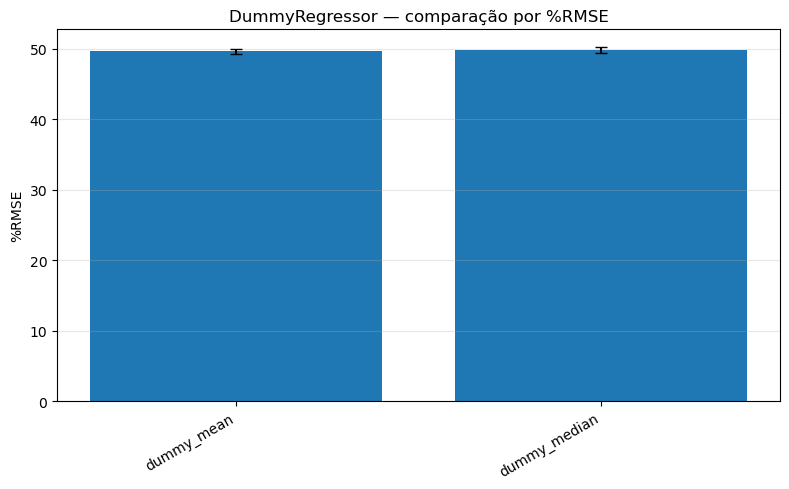

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\comparacao_RMSE_dummy.png


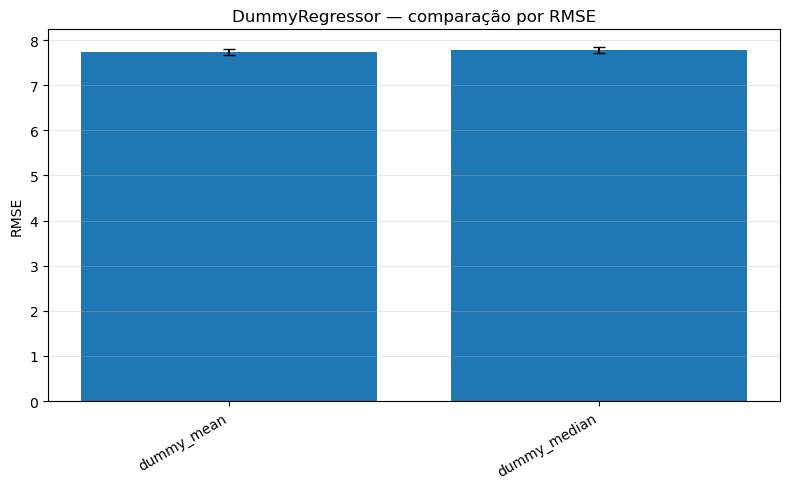

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\comparacao_MAE_dummy.png


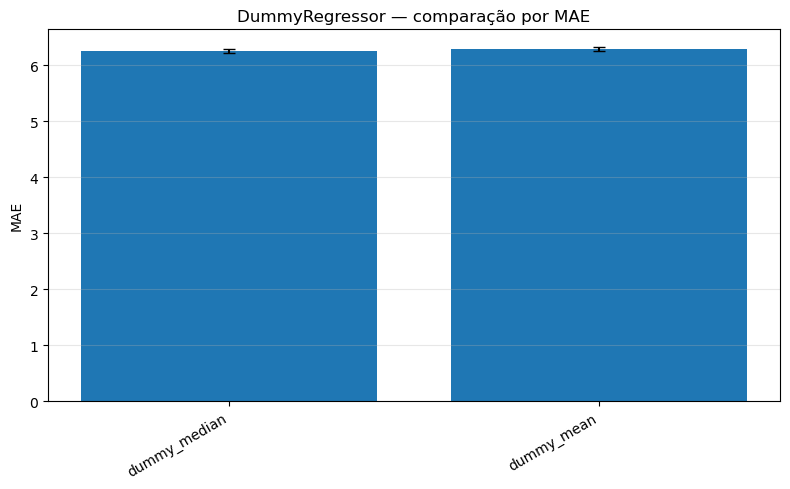

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\comparacao_R2_dummy.png


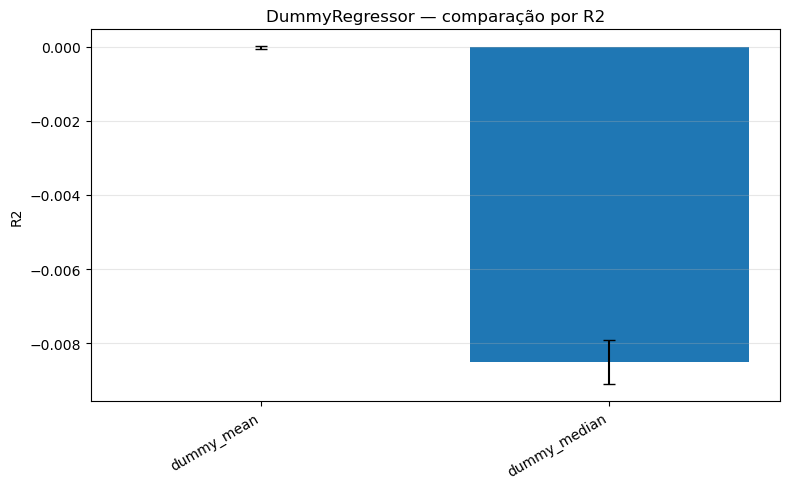

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\comparacao_Bias_dummy.png


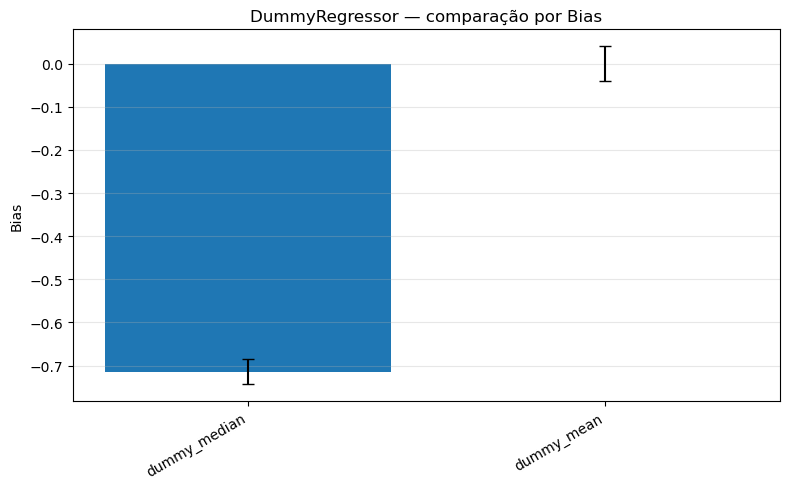

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\bias_por_classe_altura_dummy.png


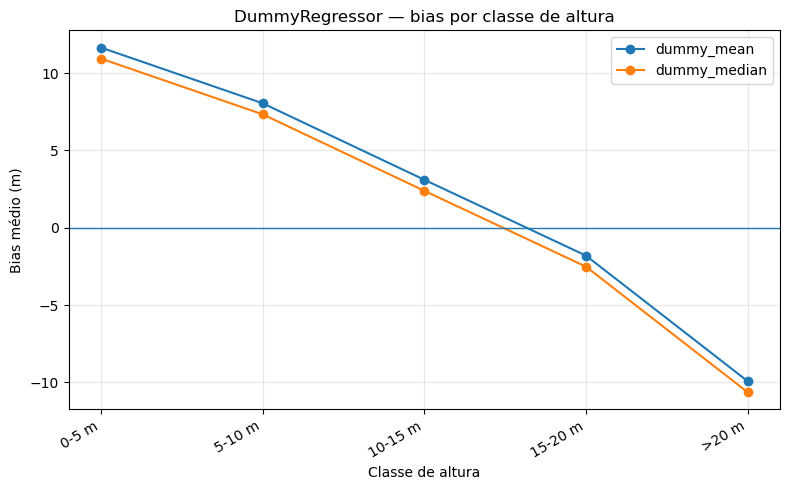

Melhor dummy por %RMSE médio nas folds: dummy_mean
Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\scatter_true_vs_pred_dummy_mean.png


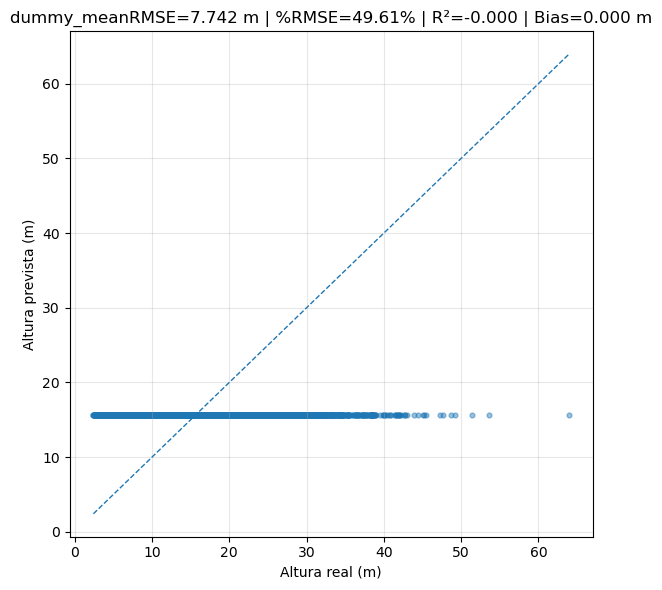

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\boxplot_abs_error_altura_dummy_mean.png


C:\Users\gui\AppData\Local\Temp\ipykernel_23928\975064163.py:189: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


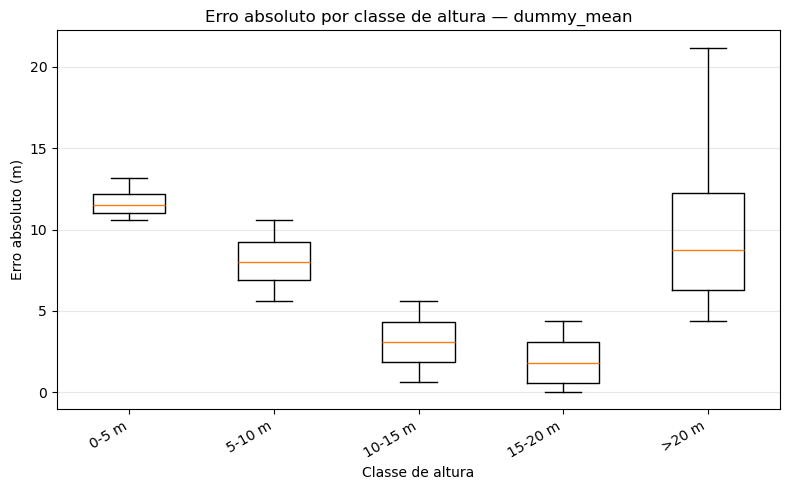

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\scatter_true_vs_pred_dummy_median.png


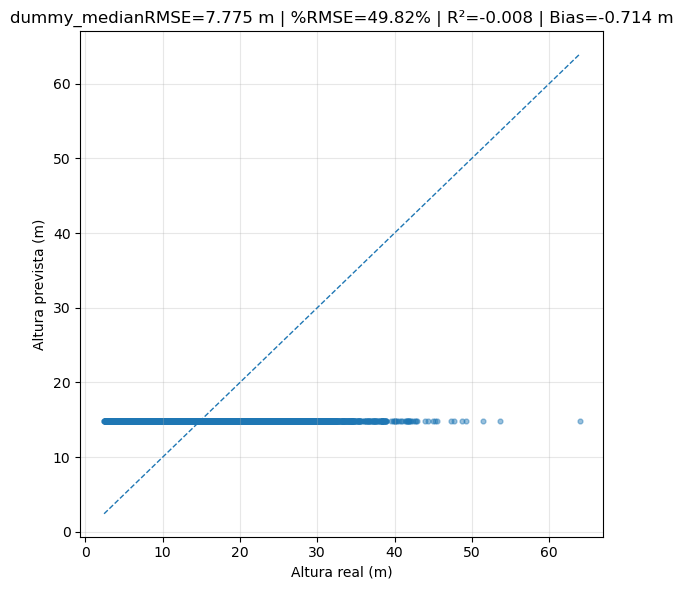

Figura guardada: outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv\figuras\boxplot_abs_error_altura_dummy_median.png


C:\Users\gui\AppData\Local\Temp\ipykernel_23928\975064163.py:189: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


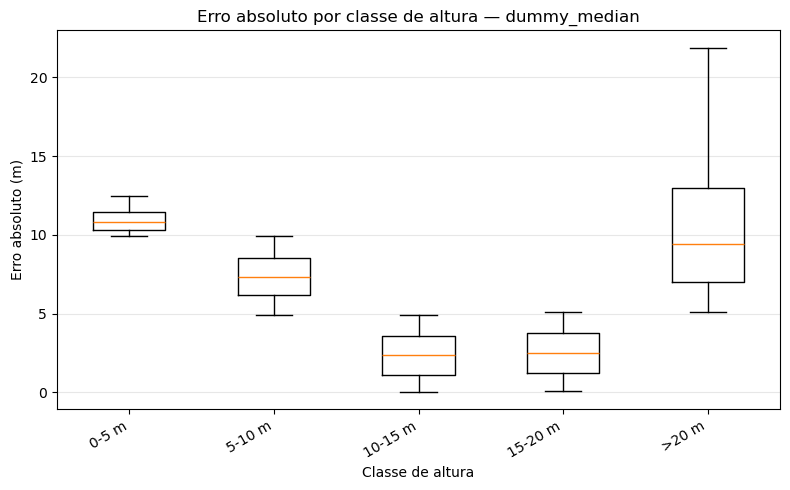

Ficheiros guardados em:
C:\Users\gui\Documents\Tese\trabalho tese\organizado\cross_validation\outputs_fch\spacial_cnn\dummy_regressor_11x11_stratified_cv


In [13]:

# ============================================================
# 8. GRÁFICOS FINAIS
# ============================================================

plot_metric_bars(fold_metrics_df)
plot_bias_by_height_class(predictions_df)

best_model = summary_flat_df.iloc[0]["model_variant"]
print(f"Melhor dummy por %RMSE médio nas folds: {best_model}")

for model_variant in summary_flat_df["model_variant"].tolist():
    plot_true_vs_pred(predictions_df, model_variant)
    plot_abs_error_boxplot_by_height_class(predictions_df, model_variant)

print("Ficheiros guardados em:")
print(OUTPUT_BASE_DIR.resolve())



## Como interpretar

O `DummyRegressor` é o baseline mínimo. Se a CNN estiver a aprender informação útil dos patches, deve ter RMSE e %RMSE claramente melhores do que o `dummy_mean`.

Normalmente, o `dummy_mean` prevê sempre a média da altura no treino de cada fold. Por isso:

- o R² tende a ficar perto de 0 ou negativo;
- o scatter fica como uma linha horizontal;
- o bias global pode ser pequeno, mas o bias por classe é forte;
- alturas baixas são sobrestimadas;
- alturas altas são subestimadas.

Este baseline é útil para justificar que os modelos CNN melhoram face a uma previsão trivial.
